# Assigment 5: Unsupervised Learning and Resampling
## Imports

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

from sklearn.metrics import precision_score, recall_score, confusion_matrix

## Question 1. Customer Segmentation with K-Means

### a) Load Data
- Source: ([https://archive.ics.uci.edu/dataset/292/wholesale+customers])
- Source: [(https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html)]

First, we load the data, and inspect the shape, data types, and missing values. We also find the minimum value, maximum value, mean, and median for each variable.

In [2]:
# fetch dataset 
wholesale_customers = fetch_ucirepo(id=292) 
  
# data (as pandas dataframes) 
X = wholesale_customers.data.features 
X = X.drop(columns=['Channel'])
  
# Show first five rows.
display(X.head(5))

# Check shape, data types, and missing values
print("Shape:", X.shape)
display(X.dtypes.to_frame(name="Data type"))
display(X.isna().sum().to_frame(name="Missing values"))

# Report summary statistics for each spending variable
summary = X.agg(["min", "max", "mean", "median"]).T
display(summary)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Shape: (440, 6)


,Data type
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


,Missing values
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


,min,max,mean,median
Fresh,3.0,112151.0,12000.297727,8504.0
Milk,55.0,73498.0,5796.265909,3627.0
Grocery,3.0,92780.0,7951.277273,4755.5
Frozen,25.0,60869.0,3071.931818,1526.0
Detergents_Paper,3.0,40827.0,2881.493182,816.5
Delicassen,3.0,47943.0,1524.870455,965.5


Each variable has an `integer` data type. Spending is continuous, but appears ti be rounded to the nearest dollar. In every category, the mean exceeds the median, indicating right-skewed spending, with a few high-spending customers raising the average. The very high maxima suggest high variation and possible outliers.

#### Plot histogram
- Source: ([https://www.geeksforgeeks.org/python/how-to-create-a-histogram-from-pandas-dataframe/])

A histogram shows how often values fall within intervals. Pandas DataFrames provide `.hist()` to create Matplotlib plots. The x-axis corresponds to the annual spending, while the y-axis corresponds to the number of customers.

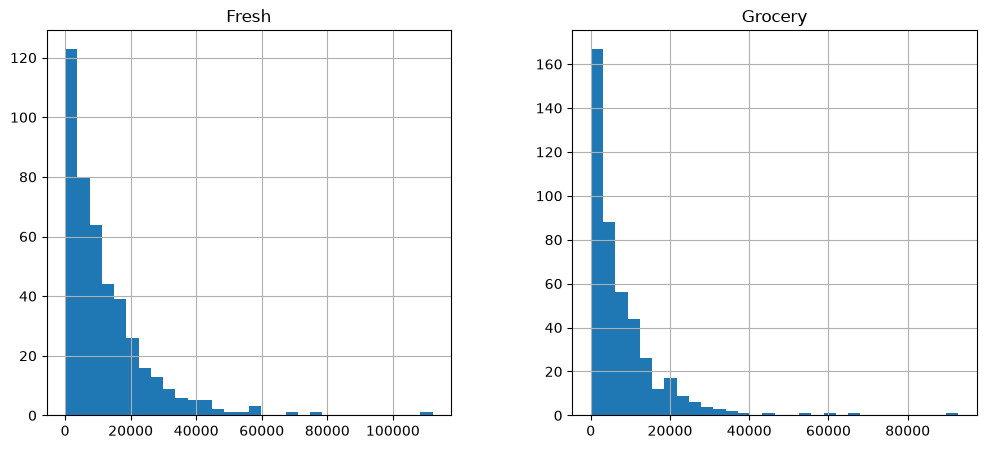

In [3]:
# Plot histograms
X[["Fresh", "Grocery"]].hist(bins=30, figsize=(12, 5))
plt.show()

Both distributions are strongly **right-skewed**. Most customers spend relatively little, while a small number of high-spening outliers spend much more. This creates a long right-tail in both plots.

### b) Data Normalization
- Source: [(https://medium.com/@noorfatimaafzalbutt/understanding-np-log-and-np-log1p-in-numpy-99cefa89cd30)]

The `log` function is often used to transform data to acheive normality is statistical models. `log1p()` calculates $\log(1 + x)$ for each element `x` in the array. This function is useful when $x$ is close to zero. It is often used in preprocessing of highly skewed data. The log transformation reduces the strong right skew and compresses extreme values, making the distributions easier to compare.

In [4]:
X_log = np.log1p(X)

#### Zero Mean and Unit Variance Normalization
- Source: ([https://www.geeksforgeeks.org/data-science/what-is-zero-mean-and-unit-variance-normalization/])

First, mean-centering subtracts each feature’s mean $\mu$, giving it a mean of zero. Then, dividing by its standard deviation $\sigma$ gives it a variance of one: $ \bar{x} = \frac{x - \mu}{\sigma}$. This can help algorithms converge faster, prevent features from dominating, and make features easier to compare. It also reduces the impact of outliers. 

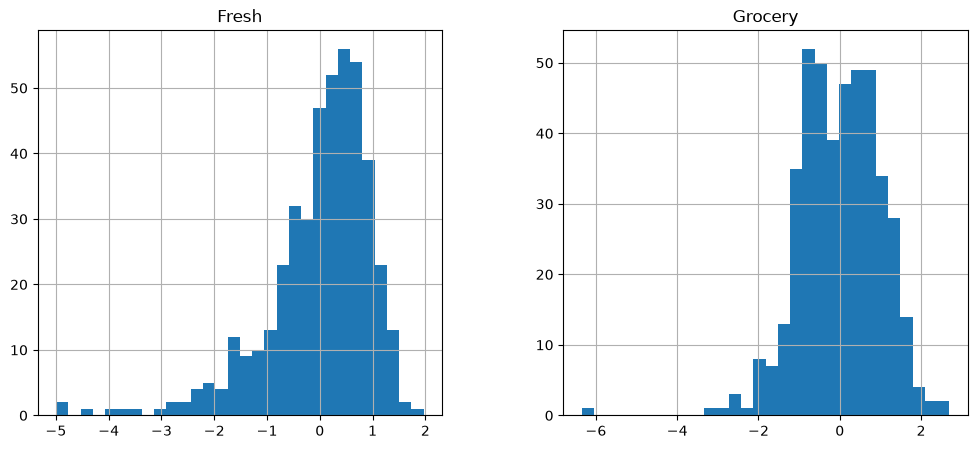

In [5]:
X_scaled = (X_log - X_log.mean()) / X_log.std()
X_scaled[["Fresh", "Grocery"]].hist(bins=30, figsize=(12, 5))
plt.show()

The original data is strongly right-skewed. The transformed and normalized data has a much more balanced distribution, though some outliers remain. The x-axis shows the normalized log-spending values. The y-axis shows the number of customers in each new bin. The total number of customers remains the same.

### c) K-Means Clustering
- Source: ([https://realpython.com/k-means-clustering-python/])

Clustering helps reveal meaningful and useful patterns in data. Three common types are partitioning, hierarchical, and density-based clustering. Partitioning divides data into non-overlapping groups. Hierarchical clustering builds a hierarchy using a bottom-up (agglomerative) or top-down (divisive) approach. Density-based clustering groups points based on their density in a region.

K-means begins by choosing $k$ centroids, where $k$ is the desired number of clusters. A centroid represents a cluster’s center. The algorithm iterates through two steps. The expectation step assigns each point to its nearest centroid. The maximization step calculates each cluster’s mean and updates its centroid. After the centroids converge, cluster quality can be assessed using the sum of squared errors (SSE), which the algorithm aims to minimize. Because initialization is random, repeated runs on the same data may produce different assignments. K-means can be implemented in Python using `scikit-learn`.

This code evaluates K-means clustering for 2 to 6 clusters. For each number of clusters $k$, we ue `fit_predict(X_scaled)` to train the model on the log-normalized data and return each point's cluster label. The model's inertia is the within-cluster squared distances, and the silhoutte score defines how well-separated the clusters are.

In [6]:
results = []

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    results.append({
        "k": k,
        "Inertia": kmeans.inertia_,
        "Silhouette score": silhouette_score(X_scaled, labels)
    })

results_table = pd.DataFrame(results)
display(results_table)

,k,Inertia,Silhouette score
0,2,1839.873014,0.290328
1,3,1549.890824,0.259416
2,4,1383.710781,0.188495
3,5,1263.271749,0.191585
4,6,1172.088727,0.200887


The results show that inertia decreases as $k$ increases, since more clusters allow the model to fit the data more closely. The silhouette score is highest at $k=2$, indicating the clearest cluster separation among the tested values, although the separation remains modest.

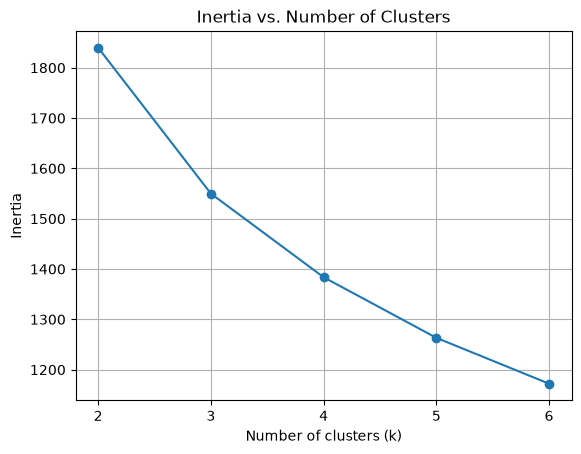

In [7]:
plt.plot(results_table["k"], results_table["Inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Inertia vs. Number of Clusters")
plt.xticks(results_table["k"])
plt.grid(True)
plt.show()

The plot shows that inertia decreases as $k$ increases. Inertia alone cannot identify the best $k$ because it always decreases as clusters are added, even if the extra clusters don't reveal any meaningful information. For example, if $k$ equals the number of data points, the model will fit the data perfectly, but will be useless.

### d) Analyze Clusters

This code fits a K-means model with $k=2$ clusters, corresponding to the model with the best silhoette score. Next, we turn the cluster labels into a labeled one-dimensional Pandas `Series`. `.value_counts()` counts how many customers have each label. `.sort_index()` orders the counts by cluster label. `.to_frame()` converts the `Series` into a one-column DataFrame for display. `.rename()` renames the `Series` to make the table clearer.


In [8]:
# Fit a separate k=2 model
kmeans_2 = KMeans(n_clusters=2, n_init=10, random_state=42)
labels_2 = kmeans_2.fit_predict(X_scaled)

# Cluster sizes
cluster_sizes = (
    pd.Series(labels_2, name="Cluster")
    .value_counts()
    .sort_index()
    .rename("Customer count")
    .to_frame())
display(cluster_sizes)

,Customer count
Cluster,
0,252
1,188


`X.assign` adds each customer's cluster label to the original untransformed data. We then use `groupby(...).median()` to calculate the median spending in each original feature for each customer.

In [9]:
# Median spending in the original, untransformed variables
X_clustered = X.assign(Cluster=labels_2)
median_spending = X_clustered.groupby("Cluster")[X.columns].median()
display(median_spending)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10347.5,1871.0,2406.0,2225.0,327.5,749.5
1,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5


To make the results easier to see, we also generate a bar graph.

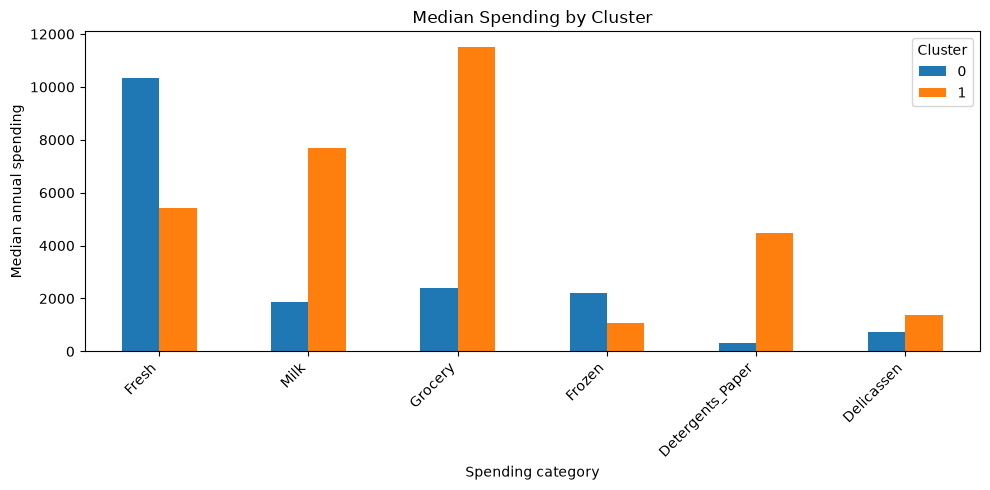

In [10]:
ax = median_spending.T.plot(kind="bar", figsize=(10, 5))
ax.set_xlabel("Spending category")
ax.set_ylabel("Median annual spending")
ax.set_title("Median Spending by Cluster")
ax.legend(title="Cluster")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Cluster 0 (252 customers) has a higher median spend on `Fresh` and lower median spending in most other categories. Cluster 1 (188 customers) spends more on `Milk`, `Grocery`, and `Detergents_Paper`. One possible explanation is that Cluster 0 includes businesses such as restaurants that need more fresh products, while Cluster 1 includes customers who buy more packaged groceries and household supplies. We name Cluster 0 `Business` and Cluster 1 `Household`. 

### e) K-Means Limitations

The clusters only show patterns in the data, they do not show what caused those patterns. The identities and characteristics of the customers are still unknown. Additionally, the silhouette score of 0.29 suggests substantial overlap between customers. Overall, the clustering revealed little meaningful structure in the data. K-means clustering assigns each customer to exactly one cluster. However, similar customers can still end up in different clusters, causing overlap between the groups. This was seen by the low silhouette score shown by this model. 

Even though the K-means results are limited, the profiles could still help a retailer target advertisements of product recommendations to certain customer types.

## Question 2. PCA and Gaussian Mixture Models
- Source: [(https://www.datacamp.com/tutorial/principal-component-analysis-in-python)]

Principal Component Analysis (PCA) reduces dataset dimensionality by transforming potentially correlated variables into a smaller set of variables called principal components that capture most of the original information. PCA helps visualize datasets with many features and is often used to preprocess data for machine-learning algorithms. Reducing dimensions can lessen the curse of dimensionality, where added features impair model performance. PCA may also reduce overfitting and multicollinearity. PCA can be describes as finding the eigenvectors of the covariance matrix to identify the directions of maximum variance in the data.

Principal components have both magnitude and direction. The direction represents across which principal axes the data has the most variance. The magnitude signifies the amount of variance that principal component captures when the data is projected onto that axis. The principal components form a straight line. The first principal component captures the most variance in the data. Each subsequent principal compoenent is orthogonal to the last and has less variance. Given a set of $x$ correlated variables over $y$ samples, we obstain a set of $u$ uncorrelated principal compoenents.

### a) Cumulative Explained Variance

We import the `PCA` module from the `sklearn` library. We choose the number of components and pass the log-normalized data. 

In [11]:
# Fit PCA using all six principal components.
pca = PCA(n_components=6)
X_pca = pca.fit_transform(X_scaled)

This code creates a table summarizing how much variance each principal component explains. The `Component` column generates the labels `PC1`, `PC2`, ect.. The `Explained variance ratio` column shows the proportional of total variance explained by each component. Numpy's `cumsum` cumultively adds those proportions, so the column `Cumulatively explained variance` shows the total variance captured by the first $n$ components.

In [12]:
variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, len(pca.explained_variance_ratio_) + 1)],
    "Explained variance ratio": pca.explained_variance_ratio_,
    "Cumulative explained variance": np.cumsum(pca.explained_variance_ratio_)})

display(variance_table)

,Component,Explained variance ratio,Cumulative explained variance
0,PC1,0.440778,0.440778
1,PC2,0.271949,0.712727
2,PC3,0.106984,0.819711
3,PC4,0.101033,0.920744
4,PC5,0.048763,0.969507
5,PC6,0.030493,1.000000


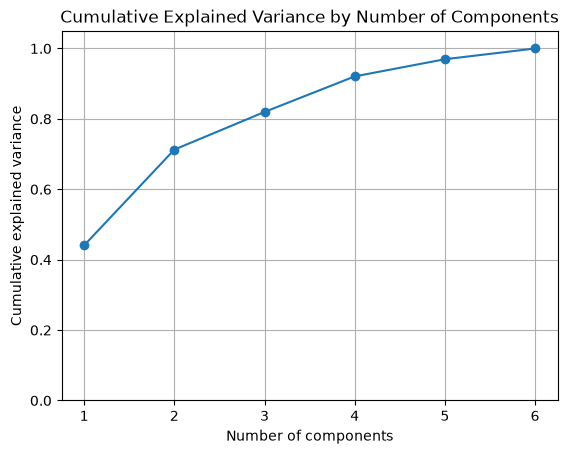

In [13]:
# Plot cumulative explained variance against the number of components
components = range(1, len(variance_table) + 1)

plt.plot(
    components,
    variance_table["Cumulative explained variance"],
    marker="o")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance by Number of Components")
plt.xticks(components)
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

PC1 explains about 44% of the variance, and PC2 adds about 27%. Together, they capture roughly 71% of the total variation. At six principal components, all of the variantion of the original dataset is captured. To retain over 90% of the original information, at least three components must be used. These results show how much we can reduce the dimensionality without losing information.

### b) 2D-Projection

This code plots `PC1` versus `PC2`, using a different color for each K-means cluster. `np.unique(labels_2)` gets the cluster labels. The mast selects the rows belonging to the current cluster. `x_pca[mask, 0]` and `x_pca[mask, 1]` get `PC1` and `PC2` data points. The x-axis shows each customer's `PC1` score, while the y-axis shows each customer's `PC2` score. The axes are labeled with their explained variance percentages.

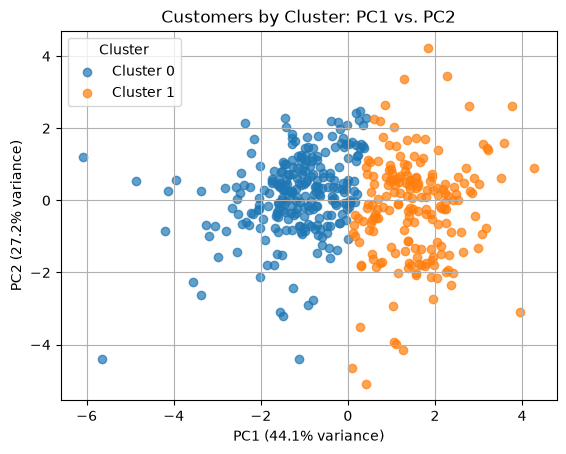

In [14]:
for cluster in np.unique(labels_2):
    mask = labels_2 == cluster
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Customers by Cluster: PC1 vs. PC2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

The clusters are partly separated along `PC1`. Cluster 0 tends to have lower scores, while Cluster 1 has higher scores. They overlap near the center so the groups are not completely distinct. The plot only shows `PC1` and `PC2` which retain about `71%` of the variation and ommits the other four components. Customer that appear close in the 2D projection may be different in the other four dimensions. This plot alone does not show how much the clusters overlap in all six dimensions. 

### c) Guassian Mixture Model
- Source: [(https://youtu.be/C7jhwN6H9LU)]
- Source: [(https://www.geeksforgeeks.org/machine-learning/gaussian-mixture-models-gmm-covariances-in-scikit-learn/)]

A Gaussian mixture model (GMM) represents data as a weighted combination of Gaussian distributions, each with its own mean and variance. Each distribution is called a component, and its weight represents the probability that a sample came from that component.

GMMs use soft clustering, which is useful when clusters overlap and data cannot be clearly separated. Unlike K-means, which assigns each data point to one cluster, a GMM gives each point a probability of belonging to every cluster. Each cluster is modeled by a Gaussian distribution.

Like K-means, GMMs use an iterative approach called expectation-maximization (EM):

1. Initialize the $k$ Gaussian distributions.
2. Calculate each data point’s responsibility, or probability of belonging to each distribution. These probabilities sum to one for each point.
3. Use the responsibilities to update the Gaussian distributions.
4. Repeat steps 2 and 3 until the model converges, meaning its parameters change very little between iterations.

For multidimensional data, each component has a mean vector and a covariance matrix. Scikit-Learn offers four covariance matrix types:
- Full: Each compoenent has its own full covariance matrix.
- Tied: All components share a single full covariance matrix. Use when components are similar.
- Diaginal: Each component has its own diagonal covariance matrix. Useful for high-dimensional data.
- Spherical: Each component has a single variance value.

This code initializes each GMM with `n_components` (number of clusters), and the `Full` covariance type. `n_init=5` runs the model with five different starting points and keeps the best fit. `reg_covar=1e-6` adds a tiny value to the covariance matrix diagonals to prevent singular matrices. Bayesian Information Criterion (BIC) compares statistical models by balancing fit against complexity (penalizing extra parameters). Lower BIC is preferred, and it can help choose the number of components.

In [16]:

gmm_results = []

for n_components in range(2, 7):
    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type="full",
        n_init=5,
        max_iter=300,
        reg_covar=1e-6,
        random_state=42
    )
    gmm.fit(X_scaled)

    gmm_results.append({
        "Components": n_components,
        "BIC": gmm.bic(X_scaled),
        "Converged": gmm.converged_,
        "Iterations": gmm.n_iter_
    })

gmm_table = pd.DataFrame(gmm_results)
display(gmm_table)

,Components,BIC,Converged,Iterations
0,2,6428.354742,True,15
1,3,6435.496265,True,10
2,4,6297.798920,True,19
3,5,6408.095117,True,20
4,6,6509.128900,True,16


The model converges in all cases, with a number of iterations much less than the `max_iter`. The 4-component model has the lowest BIC, so it is the preferred choice. 

### d) Gaussian Mixture Model Versus K-Means

Next, we assign customers to clusters using the 4-compoenent model, as it had the best BIC score. `gmm_4.predict(X_scaled)` assigns each log-normalized data point (customer) to the most likely cluster. The resulting labels are then applied to the original data, effectively assigning the original data to clusters. `X_gmm_clustered` is the original data table, but with an additional `GMM_cluster` column added. We also show a table with the number of customers assigned to each cluster.

In [17]:
# Fit a 4-component GMM and assign each customer to the component with the highest membership probability.
gmm_4 = GaussianMixture(
    n_components=4,
    covariance_type="full",
    n_init=5,
    max_iter=300,
    reg_covar=1e-6,
    random_state=42)
gmm_4.fit(X_scaled)

gmm_labels = gmm_4.predict(X_scaled)
X_gmm_clustered = X.assign(GMM_Cluster=gmm_labels)

display(X_gmm_clustered.head())
display(X_gmm_clustered["GMM_Cluster"].value_counts().sort_index().to_frame("Customer count"))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,GMM_Cluster
0,12669,9656,7561,214,2674,1338,1
1,7057,9810,9568,1762,3293,1776,2
2,6353,8808,7684,2405,3516,7844,2
3,13265,1196,4221,6404,507,1788,3
4,22615,5410,7198,3915,1777,5185,2


,Customer count
GMM_Cluster,
0,58
1,62
2,105
3,215


Next we create a scatterplot of `PC1` versus `PC2`, similar to part b). For each iteration, the `mask` is used to select that cluster's data. Then that cluster's data is added to the scatterplot.

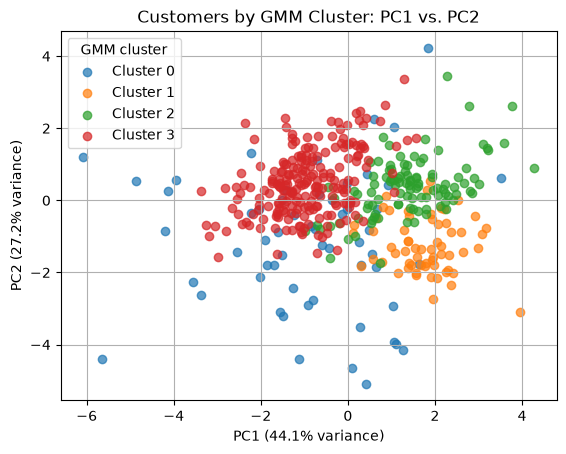

In [18]:
# Plot PC1 versus PC2, colored by GMM cluster assignments
for cluster in np.unique(gmm_labels):
    mask = gmm_labels == cluster
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Customers by GMM Cluster: PC1 vs. PC2")
plt.legend(title="GMM cluster")
plt.grid(True)
plt.show()

Both this scatterplot and the scatterplot from part b) show customer groups projected onto the first two principal components, which together explain 71.3% of the variance. The K-means plot splits the customers into two groups (left and right) along `PC1`, with some overlap near the center. The GMM divides the data into four groups. There is a large left/central group (red), two groups on the right separated by `PC2` (green and orange), and a dispersed group (blue). There is some overlap between all clusters, especially Cluster 0 (blue). K-means favors roughly spherical, similarly sized groups, when the GMM can represent groups with more varied shapes and sizes.

### e) 

Membership probability is the model's estimated probability that a data point belongs to each cluster. Each row of the `membership_probs` table corresponds to an observation in `X`, the original dataset, and sums to 1. 

In [23]:
# Membership probabilities for each customer and GMM component
membership_probs = pd.DataFrame(
    gmm_4.predict_proba(X_scaled),
    index=X.index,
    columns=[f"Component {i}" for i in range(gmm_4.n_components)])
display(membership_probs.head(5))

# Display the three customers with the lowest maximum component-membership probabilities
max_membership = membership_probs.max(axis=1)
lowest_membership = membership_probs.loc[max_membership.nsmallest(3).index].copy()

display(lowest_membership)

,Component 0,Component 1,Component 2,Component 3
0,0.004526,9.812109e-01,9.417331e-03,0.004846
1,0.000833,3.917457e-02,9.468377e-01,0.013155
2,0.002622,1.895651e-02,9.637995e-01,0.014622
3,0.006105,7.607205e-15,8.667828e-07,0.993894
4,0.002445,4.426320e-04,7.623164e-01,0.234796


,Component 0,Component 1,Component 2,Component 3
136,0.011172,0.188739,3.771371e-01,0.422952
72,0.080894,0.452858,6.446240e-09,0.466248
181,0.103623,0.000001,4.717765e-01,0.424599


Most customers have a single component with a probability over 70%, indicating a clear match. However, 26 customers do not show a clear match (ambiguous). The probability vectors for the three most ambiguous customers (136, 72, and 181) are shown. The examples show how GMMs express uncertainty. K-means gives each customer one hard cluster label, which does not indicate how confident the model is, or how plausible it is that that data point actually belongs to a different cluster.

## Question 3. Holdout, K-fold, and Stratified Cross-Validation
- Source: [(https://archive.ics.uci.edu/dataset/186/wine+quality)]

### a) Load Data
We load the UCI wine dataset, check for missing values, and remove duplicate rows. We then define a binary target: `1` if the wine quality is at least 7, and `0` if it is not.

In [25]:
# Fetch dataset
wine_quality = fetch_ucirepo(id=186)

# Features and original quality scores
X = wine_quality.data.features.copy()
y_raw = wine_quality.data.targets.copy()

# Check missing values
data = pd.concat([X, y_raw], axis=1)
display(data.isna().sum().to_frame("Missing values"))

# Remove exact duplicate rows, keeping features and targets aligned
rows_before = len(data)
data = data.drop_duplicates()
rows_removed = rows_before - len(data)

print("Duplicate rows removed:", rows_removed)
print("Rows remaining:", len(data))

# Create a binary target: 1 = quality >= 7, 0 = quality < 7
X = data[X.columns].copy()
quality = data[y_raw.columns[0]]
y = (quality >= 7).astype(int).rename("High Quality")

# Report binary class counts and proportions
class_summary = pd.DataFrame({
    "Count": y.value_counts().sort_index(),
    "Proportion": y.value_counts(normalize=True).sort_index()})
class_summary.index = ["Lower Quality (< 6)", "High Quality (>= 6)"]
display(class_summary)

,Missing values
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


Duplicate rows removed: 1179
Rows remaining: 5318


,Count,Proportion
Lower Quality (< 6),4310,0.810455
High Quality (>= 6),1008,0.189545


There are no missing values, but a large number of duplicate rows were removed. If identical rows appear in both the training and the testing dataset, test performance may look artificially high (data leakage). This evaluation will not accurately show how well the model generalizes to new data. The class proportions of this dataset are unbalanced. Most of the wine is lower quality (81%) while a smaller amount is high quality (19%). 

### b) 

We use the `train_test_split` function from `Scikit-Learn` to split the dataset into 80% training data and 20% testing data. Stratififed splitting keeps the class proportions the same in each dataset. The training dataset is then split into 75% fitting data and 25% validation data.

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train)

In [33]:
# Summarize sizes and class proportions for all three sets
split_summary = pd.DataFrame(
    {
        "Size": [len(y_fit), len(y_val), len(y_test)],
        "Share of dataset": [
            len(y_fit) / len(y),
            len(y_val) / len(y),
            len(y_test) / len(y)],
        "Lower quality proportion": [
            (y_fit == 0).mean(),
            (y_val == 0).mean(),
            (y_test == 0).mean()],
        "High quality proportion": [
            (y_fit == 1).mean(),
            (y_val == 1).mean(),
            (y_test == 1).mean()]},
    index=["Fitting", "Validation", "Test"])

display(split_summary.style.format({
    "Share of dataset": "{:.2%}",
    "Lower quality proportion": "{:.2%}",
    "High quality proportion": "{:.2%}"
}))

,Size,Share of dataset,Lower quality proportion,High quality proportion
Fitting,3190,59.98%,81.07%,18.93%
Validation,1064,20.01%,81.02%,18.98%
Test,1064,20.01%,81.02%,18.98%


#### Standardize the Predictors
- Source: [(https://towardsdatascience.com/how-and-why-to-standardize-your-data-996926c2c832/)]

Standardization prevents features with higher-magnitdue values from dominating. `StandardScaler()` standardizes each feature by subtracting its mean and dividing by its standard deviation. `fit_transform(X_fit)` learns the mean and standard deviation from the fitting data, then scales the fitting data. `transform` applies the same transformation to the validation and testing data using the mean and standard deviation from the fitting data. Fitting the `scalar` on only the fitting data prevents information leakage into the validation/test data.

In [37]:
# Fit only on the fitting data to prevent information leakage.
scaler = StandardScaler()
X_fit_scaled = pd.DataFrame(
    scaler.fit_transform(X_fit),
    index=X_fit.index,
    columns=X_fit.columns)

# Apply the same scaling to validation and test data.
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    index=X_val.index,
    columns=X_val.columns)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    index=X_test.index,
    columns=X_test.columns)

#### Model Fitting

We fit an L2-regularized logistic regression model. The `L2` penalty favors smaller coefficients to reduce overfitting. `C=1.0` sets the regularization strength, with a smaller value meaner stronger regularization. All classes are weighted equally. Next, `predict_proba()` gets the model's estimated probability of class `1` for each validation row. The next line converts probabilities into labels using a threshold of 0.5.

In [46]:
log_reg = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    class_weight=None)
log_reg.fit(X_fit_scaled, y_fit)

# Predict validation-set probabilities and apply a 0.5 threshold
y_val_probs = log_reg.predict_proba(X_val_scaled)[:, 1]
y_val_pred = (y_val_probs >= 0.5).astype(int)

c:\Users\Casey\miniconda3\envs\cpts575\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [47]:
print(f"Validation accuracy:          {accuracy_score(y_val, y_val_pred):.3f}")
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_val, y_val_pred):.3f}")
print(f"Validation F1 (class 1):      {f1_score(y_val, y_val_pred, pos_label=1):.3f}")

Validation accuracy:          0.813
Validation balanced accuracy: 0.623
Validation F1 (class 1):      0.391


The model is accurate on 83.1% of validation examples, but its balancing accuracy is lower at 62.3%, meaning it may favor the more common class. The class 1 F1 of 0.391 shows that the model is not doing well identifying positive cases (high quality), which makes sense as these cases are less common. This forms the single-holdout estimate, which evaluates the model on one split of the data. The results vary highly depending on which cases end up in the split.

### c)

#### Ordinary K-fold Validation
- Source: ([https://www.geeksforgeeks.org/machine-learning/cross-validation-using-k-fold-with-scikit-learn/])

K-Fold cross-validation divides the dataset into K equal parts (folds) and trains the model multiple times, each time suring a different fold as the test set, and the remaining folds as the training data. `make_pipeline` connects preprocessing and logistic regression fitting, so we can more conveniently perform those steps in order for each fold. The data is standardized separately for each fold. The `scalar` is fit only on that fold's training portion to prevent data leakage. `KFold` is not stratified, so the class proportions may differ across folds. For each fold, we record its size and class 1 percentage. We also record accuracy, balanced accuracy, and class F1. We display the results in a table.

In [49]:
# Ordinary (non-stratified) 5-fold CV on the full 80% training set.
# Scaling is fitted separately within each fold to prevent data leakage.
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train), start=1):
    
    # Create fold
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Chain preprocessing and model fitting
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="lbfgs",
            max_iter=1000,
            class_weight=None))
    model.fit(X_fold_train, y_fold_train)
    y_fold_pred = model.predict(X_fold_val)

    fold_results.append({
        "Fold": fold,
        "Validation size": len(y_fold_val),
        "Class 1 (%)": 100 * y_fold_val.mean(),
        "Accuracy": accuracy_score(y_fold_val, y_fold_pred),
        "Balanced accuracy": balanced_accuracy_score(y_fold_val, y_fold_pred),
        "Class 1 F1": f1_score(y_fold_val, y_fold_pred, pos_label=1)
    })

fold_results_table = pd.DataFrame(fold_results)
display(fold_results_table.round(3))

c:\Users\Casey\miniconda3\envs\cpts575\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Casey\miniconda3\envs\cpts575\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Casey\miniconda3\envs\c

,Fold,Validation size,Class 1 (%),Accuracy,Balanced accuracy,Class 1 F1
0,1,851,19.154,0.826,0.609,0.362
1,2,851,20.447,0.805,0.623,0.399
2,3,851,18.684,0.832,0.635,0.416
3,4,851,18.684,0.828,0.618,0.381
4,5,850,17.765,0.827,0.622,0.385


In [50]:
metrics = ["Accuracy", "Balanced accuracy", "Class 1 F1"]
cv_summary = (
    fold_results_table[metrics]
    .agg(["mean", "std"])
    .T
    .rename(columns={"mean": "Mean", "std": "Sample SD"}))
display(cv_summary.round(3))

,Mean,Sample SD
Accuracy,0.824,0.011
Balanced accuracy,0.622,0.009
Class 1 F1,0.389,0.020


Across the five folds, accuracy is consistently high. However, the mean balanced accuracy is lower. Class 1 only makes up 18-20% of each fold, and the class 1 F1 score is low, showing that the model is worse at predicting Class 1. Results are fairly consistent, but Class 1 varies slightly more, with a slightly higher standard deviation.

#### Stratified K-Fold Validation

Now we repeat the exact same procedure for stratified K-Fold cross-validation.

In [52]:
# Stratified 5-fold CV on the full training set.
# Each fold preserves approximately the same class proportions.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
stratified_fold_results = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="lbfgs",
            max_iter=1000,
            class_weight=None
        )
    )
    model.fit(X_fold_train, y_fold_train)
    y_fold_pred = model.predict(X_fold_val)

    stratified_fold_results.append({
        "Fold": fold,
        "Validation size": len(y_fold_val),
        "Class 1 (%)": 100 * y_fold_val.mean(),
        "Accuracy": accuracy_score(y_fold_val, y_fold_pred),
        "Balanced accuracy": balanced_accuracy_score(y_fold_val, y_fold_pred),
        "Class 1 F1": f1_score(y_fold_val, y_fold_pred, pos_label=1)
    })

stratified_fold_results_table = pd.DataFrame(stratified_fold_results)
display(stratified_fold_results_table.round(3))

metrics = ["Accuracy", "Balanced accuracy", "Class 1 F1"]
stratified_cv_summary = (
    stratified_fold_results_table[metrics]
    .agg(["mean", "std"])
    .T
    .rename(columns={"mean": "Mean", "std": "Sample SD"}))
display(stratified_cv_summary.round(3))

c:\Users\Casey\miniconda3\envs\cpts575\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Casey\miniconda3\envs\cpts575\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Casey\miniconda3\envs\c

,Fold,Validation size,Class 1 (%),Accuracy,Balanced accuracy,Class 1 F1
0,1,851,18.919,0.813,0.604,0.351
1,2,851,18.919,0.827,0.629,0.405
2,3,851,18.919,0.833,0.638,0.423
3,4,851,19.036,0.826,0.623,0.393
4,5,850,18.941,0.820,0.618,0.381


,Mean,Sample SD
Accuracy,0.824,0.008
Balanced accuracy,0.622,0.013
Class 1 F1,0.391,0.027


The mean accuracy and mean balanced accuracy remain approximately unchanged for the stratified k-fold validation. The Class 1 F1-score is also similar for the stratified versus non-stratified case. The non-stratified folds vary more in class composition, but the performance is not meaningfully different. 

### d) Compare all methods in one table.

In [53]:
# Compare the single-holdout validation estimate with the two cross-validation estimates.
comparison = pd.DataFrame(
    {
        "Method": [
            "Single holdout",
            "Unstratified 5-fold CV",
            "Stratified 5-fold CV"],
        "Accuracy": [
            accuracy_score(y_val, y_val_pred),
            cv_summary.loc["Accuracy", "Mean"],
            stratified_cv_summary.loc["Accuracy", "Mean"]],
        "Balanced accuracy": [
            balanced_accuracy_score(y_val, y_val_pred),
            cv_summary.loc["Balanced accuracy", "Mean"],
            stratified_cv_summary.loc["Balanced accuracy", "Mean"]],
        "Class 1 F1": [
            f1_score(y_val, y_val_pred, pos_label=1),
            cv_summary.loc["Class 1 F1", "Mean"],
            stratified_cv_summary.loc["Class 1 F1", "Mean"]],
        "Accuracy SD": [
            np.nan,
            cv_summary.loc["Accuracy", "Sample SD"],
            stratified_cv_summary.loc["Accuracy", "Sample SD"]],
        "Balanced accuracy SD": [
            np.nan,
            cv_summary.loc["Balanced accuracy", "Sample SD"],
            stratified_cv_summary.loc["Balanced accuracy", "Sample SD"]],
        "Class 1 F1 SD": [
            np.nan,
            cv_summary.loc["Class 1 F1", "Sample SD"],
            stratified_cv_summary.loc["Class 1 F1", "Sample SD"]]}
).set_index("Method")

display(comparison.round(3))

,Accuracy,Balanced accuracy,Class 1 F1,Accuracy SD,Balanced accuracy SD,Class 1 F1 SD
Method,,,,,,
Single holdout,0.813,0.623,0.391,NaN,NaN,NaN
Unstratified 5-fold CV,0.824,0.622,0.389,0.011,0.009,0.020
Stratified 5-fold CV,0.824,0.622,0.391,0.008,0.013,0.027


All methods produce similar mean accuracy, mean balanced accuracy, and Class 1 F1. The unstratified k-folds validation shows slightly higher accuracy, balanaced accuracy, and Class 1 F1-score standard deviation. Stratification preserves the class proportions in each training/testing dataset. High accuracy alone can hide poor minority-class performance, because the model will still classify most examples correctly by only predicting the majority class. Scaling the complete training set before cross-validation would allow the validation data to influence the scaling mean and standard deviation, casuing information leakage. 

### e) Evalutate on Test Set

We scale the data and fit the model on the original training set, and evaluate once on the untouched test set. We find the accuracy, balanced accuracy, class-1 precision, recall, and F1. Finally, we plot the confusion matrix.

c:\Users\Casey\miniconda3\envs\cpts575\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Test accuracy:          0.819
Test balanced accuracy: 0.632
Class 1 precision:      0.536
Class 1 recall:         0.332
Class 1 F1:             0.410


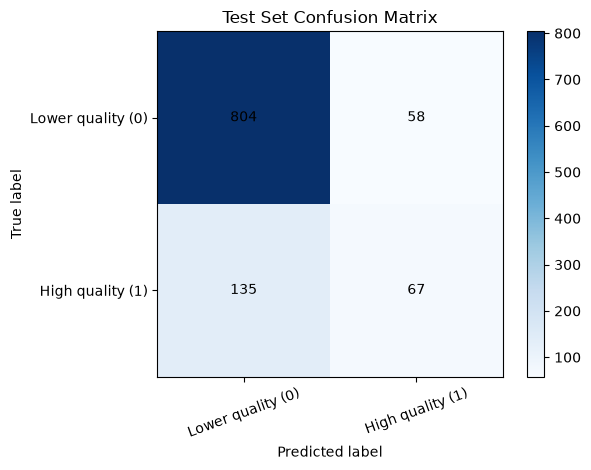

In [55]:
# Refit preprocessing and the fixed logistic regression model on the full training set
final_scaler = StandardScaler()
X_train_scaled = final_scaler.fit_transform(X_train)
X_test_scaled = final_scaler.transform(X_test)

final_log_reg = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    class_weight=None)
final_log_reg.fit(X_train_scaled, y_train)

# Evaluate once on the untouched test set
y_test_pred = final_log_reg.predict(X_test_scaled)

print(f"Test accuracy:          {accuracy_score(y_test, y_test_pred):.3f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, y_test_pred):.3f}")
print(f"Class 1 precision:      {precision_score(y_test, y_test_pred, pos_label=1):.3f}")
print(f"Class 1 recall:         {recall_score(y_test, y_test_pred, pos_label=1):.3f}")
print(f"Class 1 F1:             {f1_score(y_test, y_test_pred, pos_label=1):.3f}")

# Plot confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

plt.imshow(cm, cmap="Blues")
plt.title("Test Set Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks([0, 1], ["Lower quality (0)", "High quality (1)"], rotation=20)
plt.yticks([0, 1], ["Lower quality (0)", "High quality (1)"])

for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        plt.text(col, row, cm[row, col], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

The model tends to perform better on low-quality examples. It identifies only 67 of 202 high-quality cases. 

#### Compare with always-0 baseline

In [56]:
# Compare the model with an always-predict-0 baseline
y_test_baseline = np.zeros_like(y_test)

baseline_comparison = pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(y_test, y_test_pred),
            accuracy_score(y_test, y_test_baseline)],
        "Balanced accuracy": [
            balanced_accuracy_score(y_test, y_test_pred),
            balanced_accuracy_score(y_test, y_test_baseline)]
    },
    index=["Logistic regression", "Always predict 0"])

display(baseline_comparison.round(3))

,Accuracy,Balanced accuracy
Logistic regression,0.819,0.632
Always predict 0,0.810,0.500


The model shows little usefulness. Its test accuracy is only very slightly above the always-predict-0 baseline. The model's higher balanced accuracy (0.632 vs. 0.500) shows it does detect some high-quality cases. The cross-validation accuracy mean is an estimate across different training/validation splits, the model was never evaluated on the test set, which contains diffferent examples. As a result, the accuracy on the testing dataset may have different results.